In [ ]:
import os 
import numpy as np 
from glob import glob
from astropy.io import fits
from matplotlib import pyplot as plt
raw_input_dir = '/data/beegfs/astro-storage/groups/beuther/pasteimle/ISPY_raw_files/'

# input_dir = '/data/beegfs/astro-storage/groups/beuther/pasteimle/HD59659_all_raw_files/'
# output_dir = '/data/beegfs/astro-storage/groups/beuther/pasteimle/HD59659_all_reduced_files/'



all_stars = [f for f in os.listdir(raw_input_dir) if f not in ['FLAT','DARK', 'DB_H23', 'BACKGROUND', 'DISTORT', 'DARK,BACKGROUND', 'recentering']] 

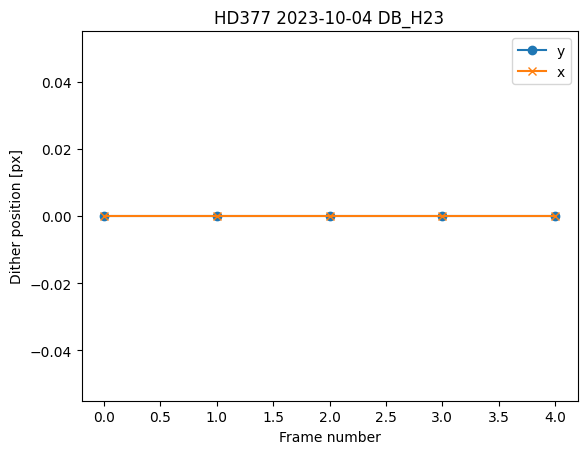

In [77]:
all_stars = ['HD377']

for star in all_stars:

        star_parent_dir = os.path.join(raw_input_dir,star,'IRDIS')
        all_obs_nights = os.listdir(star_parent_dir)
        for obs_night in all_obs_nights:

            obs_night_parent_dir = os.path.join(star_parent_dir,obs_night)
            filters = os.listdir(obs_night_parent_dir)

            for filter_name in filters:

                science_files = sorted(glob(os.path.join(obs_night_parent_dir,filter_name,'SKY*.fits')))



                all_n_exp = np.zeros(len(science_files)) * np.nan
                x_array = np.zeros(len(science_files)) * np.nan 
                y_array = np.zeros(len(science_files))* np.nan
                for i, file in enumerate(science_files):
                    header = fits.getheader(file)
                    all_n_exp[i] = header['HIERARCH ESO DET NDIT']
                    x_array[i] = header['HIERARCH ESO INS1 DITH POSX']
                    y_array[i] = header['HIERARCH ESO INS1 DITH POSY']



                total_n_frames = int(np.sum(all_n_exp))
                len_files = np.arange(total_n_frames)
                x_shift = np.zeros(total_n_frames) * np.nan 
                y_shift = np.zeros(total_n_frames) * np.nan

                k = 0
                for i, n_exp in enumerate(all_n_exp):
                    for j in range(int(n_exp)):
                        x_shift[k] = int(x_array[i])
                        y_shift[k] = int(y_array[i])
                        k += 1


                plt.plot(len_files,y_shift, linestyle='-', marker='o', label='y')
                plt.plot(len_files,x_shift, linestyle='-', marker='x', label='x')
                plt.xlabel('Frame number')
                plt.ylabel('Dither position [px]')
                plt.legend()
                
                plt.title(star + ' ' + obs_night + ' ' + filter_name)

In [70]:
y_shift = np.int64(y_shift)
x_shift = np.int64(x_shift)

In [32]:
from HCIutils import show_img

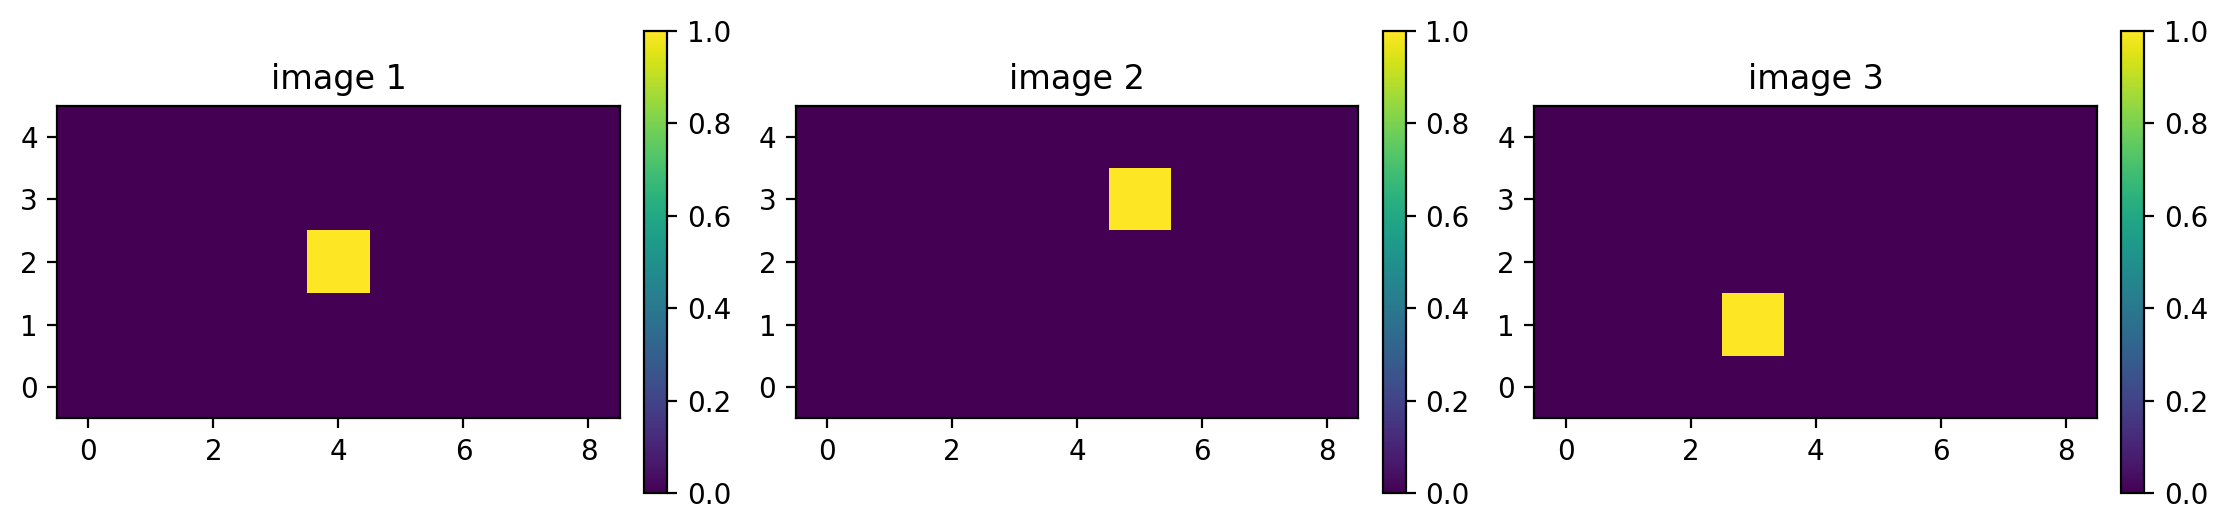

In [73]:
image = np.zeros((3,5,9)) 
image[:,2,4] = 1


y_shift = np.array([0,1,-1])
x_shift = np.array([0,1,-1])

for i in range(image.shape[0]):
    image[i] = np.roll(image[i], (y_shift[i], x_shift[i]), axis=(0, 1))

show_img([image[0], image[1], image[2]], vmin=0, vmax=1)